## Step 5: Connecting Python to SQL

### 5.1 Connect Python to  SQL database

In [1]:
%pip install mysql-connector-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
from sqlalchemy import create_engine, URL

username = "root"
password = "Vachas@1996"
host = "localhost"
port = 3306
database = "financial_performance"

connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username=username,
    password=password,
    host=host,
    port=port,
    database=database
)

engine = create_engine(connection_url)

print("Engine created successfully!")

Engine created successfully!


### 5.2 Load all the tables to Pandas DataFrames

In [3]:
import pandas as pd

customers_df = pd.read_sql("select * from customers", engine)
vendors_df = pd.read_sql("select * from vendors", engine)
headcount_df = pd.read_sql("select * from headcount", engine)
budget_df = pd.read_sql("select * from budget", engine)
transactions_df = pd.read_sql("select * from financial_transactions", engine)

### 5.3 Validate schema and row counts

#### Dataframe size check

In [4]:
print("customers:", customers_df.shape)
print("vendors:", vendors_df.shape)
print("headcount:", headcount_df.shape)
print("budget:", budget_df.shape)
print("financial_transactions:", transactions_df.shape)

customers: (400, 6)
vendors: (120, 5)
headcount: (200, 7)
budget: (72, 5)
financial_transactions: (10400, 10)


**Inference:** All tables are successfully loaded with correct numbers of rows and columns

#### Datatype check for each df

In [5]:
print("\nCustomer DataFrame:")
print(customers_df.dtypes)

print("\nVendors DataFrame:")
print(vendors_df.dtypes)

print("\nHeadcount DataFrame:")
print(headcount_df.dtypes)

print("\nBudget DataFrame:")
print(budget_df.dtypes)

print("\nFinancial Transactions DataFrame:")
print(transactions_df.dtypes)


Customer DataFrame:
customer_id      object
customer_name    object
segment          object
join_date        object
region           object
status           object
dtype: object

Vendors DataFrame:
vendor_id      object
vendor_name    object
category       object
region         object
active         object
dtype: object

Headcount DataFrame:
employee_id        object
employee_name      object
business_unit      object
join_date          object
status             object
region             object
cost_to_company     int64
dtype: object

Budget DataFrame:
year                 int64
month                int64
business_unit       object
budgeted_revenue     int64
budgeted_expense     int64
dtype: object

Financial Transactions DataFrame:
transaction_id       object
transaction_date     object
amount              float64
account_type         object
category             object
business_unit        object
region               object
customer_id          object
vendor_id            object
desc

#### Converting date columns dtype to correct format

In [6]:
transactions_df["transaction_date"]=pd.to_datetime(transactions_df["transaction_date"])
customers_df["join_date"]=pd.to_datetime(customers_df["join_date"])
headcount_df["join_date"]=pd.to_datetime(headcount_df["join_date"])


#### Recheck for correct dtypes

In [7]:
print("\nCustomer DataFrame:")
print(customers_df.dtypes)

print("\nVendors DataFrame:")
print(vendors_df.dtypes)

print("\nHeadcount DataFrame:")
print(headcount_df.dtypes)

print("\nBudget DataFrame:")
print(budget_df.dtypes)

print("\nFinancial Transactions DataFrame:")
print(transactions_df.dtypes)


Customer DataFrame:
customer_id              object
customer_name            object
segment                  object
join_date        datetime64[ns]
region                   object
status                   object
dtype: object

Vendors DataFrame:
vendor_id      object
vendor_name    object
category       object
region         object
active         object
dtype: object

Headcount DataFrame:
employee_id                object
employee_name              object
business_unit              object
join_date          datetime64[ns]
status                     object
region                     object
cost_to_company             int64
dtype: object

Budget DataFrame:
year                 int64
month                int64
business_unit       object
budgeted_revenue     int64
budgeted_expense     int64
dtype: object

Financial Transactions DataFrame:
transaction_id              object
transaction_date    datetime64[ns]
amount                     float64
account_type                object
category    

**Inference:** All dataframes have correctly matched dtypes now

#### Dataframe Preview

In [8]:
print("Customer DataFrame:")
print(customers_df.head())

print("\nVendors DataFrame:")
print(vendors_df.head())

print("\nHeadcount DataFrame:")
print(headcount_df.head())

print("\nBudget DataFrame:")
print(budget_df.head())

print("\nFinancial Transactions DataFrame:")
print(transactions_df.head())

Customer DataFrame:
  customer_id             customer_name     segment  join_date region  status
0   CUST10000  Johnson, Olson and Smith      Online 2020-03-28  North  Active
1   CUST10001              Colon-Valdez  Enterprise 2018-02-15   West  Active
2   CUST10002   Henry, Jones and Farley      Online 2022-03-21  North  Active
3   CUST10003           Williams-Dalton      Retail 2021-03-22   West  Active
4   CUST10004            Fisher-Serrano  Enterprise 2018-11-02   East  Active

Vendors DataFrame:
  vendor_id                vendor_name    category region active
0  VEND1000             Johnson-Howard    Supplies   East      Y
1  VEND1001                 Jensen Ltd  Consulting  South      Y
2  VEND1002              Collins Group    Services  North      Y
3  VEND1003    Smith, Kirby and Torres   Utilities  North      Y
4  VEND1004  Mcgrath, Wheeler and Boyd   Utilities  North      Y

Headcount DataFrame:
  employee_id    employee_name business_unit  join_date  status region  \
0     

**Inference:** All tables preview check completed.

## STEP 6: Data cleaning, transformation and EDA

### 6.1 Missing values


In [9]:
print("Customers:")
print(customers_df.isnull().sum())

print("\nVendors:")
print(vendors_df.isnull().sum())

print("\nHeadcount:")
print(headcount_df.isnull().sum())

print("\nBudget:")
print(budget_df.isnull().sum())

print("\nFinancial Transactions:")
print(transactions_df.isnull().sum())

Customers:
customer_id      0
customer_name    0
segment          0
join_date        0
region           0
status           0
dtype: int64

Vendors:
vendor_id      0
vendor_name    0
category       0
region         0
active         0
dtype: int64

Headcount:
employee_id        0
employee_name      0
business_unit      0
join_date          0
status             0
region             0
cost_to_company    0
dtype: int64

Budget:
year                0
month               0
business_unit       0
budgeted_revenue    0
budgeted_expense    0
dtype: int64

Financial Transactions:
transaction_id         0
transaction_date       0
amount                 0
account_type           0
category               0
business_unit          0
region                 0
customer_id         4886
vendor_id           6275
description            0
dtype: int64


**Inference:** There are no missing values in customer_df, vendors_df, budget_df, headcount_df.
transactions_df shows missing values in column 'customer_id' and 'vendor_id' but that is by design since each row can take value in either column and not both at same time.  
Conclusion: There are no missing values in any table.

**Decision: No imputation.** The only blanks are `customer_id` and `vendor_id`. A customer ID is only meant to exist on Revenue rows and a vendor ID only on Expense rows, so these blanks are valid, not missing data. All other columns are complete.

### 6.2 Revenue and Expense statistics

In [10]:
revenue_df = transactions_df[
    transactions_df["account_type"] == "Revenue"
].copy()

expense_df = transactions_df[
    transactions_df["account_type"] == "Expense"
].copy()

expense_df["amount"] = expense_df["amount"].abs()

In [11]:
print("\nStatistics for Revenue")
print(revenue_df["amount"].describe())
print("IQR:", revenue_df["amount"].quantile(0.75) -
            revenue_df["amount"].quantile(0.25))

print("\nStatistics for Expenses")
print(expense_df["amount"].describe())
print("IQR:", expense_df["amount"].quantile(0.75) -
            expense_df["amount"].quantile(0.25))


Statistics for Revenue
count      5514.000000
mean     156802.428763
std       51989.980218
min        5000.000000
25%      121379.810000
50%      153910.430000
75%      190384.737500
max      351386.850000
Name: amount, dtype: float64
IQR: 69004.92750000002

Statistics for Expenses
count      4125.000000
mean      40664.557527
std       19232.926149
min        2000.000000
25%       27137.340000
50%       40510.710000
75%       53648.500000
max      113310.710000
Name: amount, dtype: float64
IQR: 26511.16


**Summary:**  
Revenue transactions have a higher average value (156,802) than expenses (40,665). For both revenue and expenses, the mean and median are relatively close, suggesting no extreme skew in the typical transaction values. Revenue also shows greater variability, with a standard deviation of 51,990 and IQR of 69,005, compared with 19,233 and 26,511 for expenses. The maximum revenue transaction (351,387) is substantially higher than the maximum expense (113,311), indicating greater dispersion in revenue transaction sizes.

### 6.3 Profit Statistics

In [12]:
profit_df = transactions_df[
    transactions_df["account_type"].isin(["Revenue", "Expense"])
].copy()

profit_df["month"] = profit_df["transaction_date"].dt.to_period("M")

monthly_profit = (
    profit_df.groupby("month")["amount"]
    .sum()
    .reset_index(name="profit")
)

print("\nStatistics for Monthly Profit")
print(monthly_profit["profit"].describe())

print(
    "IQR:",
    monthly_profit["profit"].quantile(0.75)
    - monthly_profit["profit"].quantile(0.25)
)


Statistics for Monthly Profit
count    2.400000e+01
mean     2.903614e+07
std      7.898771e+06
min      1.665882e+07
25%      2.493472e+07
50%      2.696949e+07
75%      3.145540e+07
max      4.648622e+07
Name: profit, dtype: float64
IQR: 6520678.810000002


**Summary:**  
Monthly profit averaged approximately ₹29.04 million, with a median of ₹26.97 million. Monthly profit ranged from ₹16.66 million to ₹46.49 million, with an IQR of ₹6.52 million, indicating some variation in profitability across months. The mean being higher than the median suggests that a few months with relatively high profits may be influencing the average.

### 6.4 Budget Variance Statistics

In [13]:
# Adding year and month
revenue_df["year"] = revenue_df["transaction_date"].dt.year
revenue_df["month"] = revenue_df["transaction_date"].dt.month

expense_df["year"] = expense_df["transaction_date"].dt.year
expense_df["month"] = expense_df["transaction_date"].dt.month

# Calculating actual revenue
actual_revenue = revenue_df.groupby(
    ["year", "month", "business_unit"]
)["amount"].sum().reset_index()

# Calculating actual expense
actual_expense = expense_df.groupby(
    ["year", "month", "business_unit"]
)["amount"].sum().reset_index()

print("Actual Revenue:")
print(actual_revenue.head())

print("\nActual Expense:")
print(actual_expense.head())

Actual Revenue:
   year  month business_unit      amount
0  2022      1    Enterprise  9000016.39
1  2022      1        Online  9222358.75
2  2022      1        Retail  7315722.74
3  2022      2    Enterprise  7457335.63
4  2022      2        Online  6751487.05

Actual Expense:
   year  month business_unit      amount
0  2022      1    Enterprise  2257337.53
1  2022      1        Online  2836633.16
2  2022      1        Retail  2305293.23
3  2022      2    Enterprise  2406861.49
4  2022      2        Online  2030405.65


In [14]:
# Adding actual revenue to the budget table
budget_variance_df = budget_df.merge(
    actual_revenue,
    on=["year", "month", "business_unit"],
    how="left"
)

# Renaming the actual revenue column
budget_variance_df = budget_variance_df.rename(
    columns={"amount": "actual_revenue"}
)

# Adding actual expense
budget_variance_df = budget_variance_df.merge(
    actual_expense,
    on=["year", "month", "business_unit"],
    how="left"
)

# Renaming the actual expense column
budget_variance_df = budget_variance_df.rename(
    columns={"amount": "actual_expense"}
)

print(budget_variance_df.head())

   year  month business_unit  budgeted_revenue  budgeted_expense  \
0  2022      1    Enterprise           1689240           1152615   
1  2022      1        Online           2069088           1776169   
2  2022      1        Retail           1530660           1259760   
3  2022      2    Enterprise           1923012           1454263   
4  2022      2        Online           1516272           1117069   

   actual_revenue  actual_expense  
0      9000016.39      2257337.53  
1      9222358.75      2836633.16  
2      7315722.74      2305293.23  
3      7457335.63      2406861.49  
4      6751487.05      2030405.65  


In [15]:
# Calculating budget variance

budget_variance_df["revenue_variance"] = (
    budget_variance_df["actual_revenue"]
    - budget_variance_df["budgeted_revenue"]
)

budget_variance_df["expense_variance"] = (
    budget_variance_df["actual_expense"]
    - budget_variance_df["budgeted_expense"]
)

print(budget_variance_df.head())

   year  month business_unit  budgeted_revenue  budgeted_expense  \
0  2022      1    Enterprise           1689240           1152615   
1  2022      1        Online           2069088           1776169   
2  2022      1        Retail           1530660           1259760   
3  2022      2    Enterprise           1923012           1454263   
4  2022      2        Online           1516272           1117069   

   actual_revenue  actual_expense  revenue_variance  expense_variance  
0      9000016.39      2257337.53        7310776.39        1104722.53  
1      9222358.75      2836633.16        7153270.75        1060464.16  
2      7315722.74      2305293.23        5785062.74        1045533.23  
3      7457335.63      2406861.49        5534323.63         952598.49  
4      6751487.05      2030405.65        5235215.05         913336.65  


In [16]:
print("Revenue Variance")
print(budget_variance_df["revenue_variance"].describe())

print("\nExpense Variance")
print(budget_variance_df["expense_variance"].describe())

print("\nRevenue Variance IQR:")
print(
    budget_variance_df["revenue_variance"].quantile(0.75)
    - budget_variance_df["revenue_variance"].quantile(0.25)
)

print("\nExpense Variance IQR:")
print(
    budget_variance_df["expense_variance"].quantile(0.75)
    - budget_variance_df["expense_variance"].quantile(0.25)
)

Revenue Variance
count    7.200000e+01
mean     1.012215e+07
std      2.774750e+06
min      4.951474e+06
25%      8.233544e+06
50%      9.793070e+06
75%      1.185877e+07
max      1.651450e+07
Name: revenue_variance, dtype: float64

Expense Variance
count    7.200000e+01
mean     8.816115e+05
std      4.522048e+05
min     -4.476039e+05
25%      6.908541e+05
50%      9.363507e+05
75%      1.079735e+06
max      1.963871e+06
Name: expense_variance, dtype: float64

Revenue Variance IQR:
3625229.070000001

Expense Variance IQR:
388880.7449999999


**Summary:**  
Revenue variance was positive across all 72 budget records, with an average variance of approximately 10.12 million, indicating that actual revenue consistently exceeded the budget. Expense variance averaged approximately 0.88 million, meaning expenses were generally above budget. However, the minimum expense variance was −0.45 million, showing that some periods had expenses below budget. Revenue variance also showed greater variability than expense variance, with IQRs of approximately 3.63 million and 0.39 million, respectively.

In [17]:
keys = ["year", "month", "business_unit"]

# Add year and month to both tables
for df in (revenue_df, expense_df):
    df["year"] = df["transaction_date"].dt.year
    df["month"] = df["transaction_date"].dt.month

# Total actuals per year, month and business unit
actual_revenue = revenue_df.groupby(keys, as_index=False)["amount"].sum().rename(columns={"amount": "actual_revenue"})
actual_expense = expense_df.groupby(keys, as_index=False)["amount"].sum().rename(columns={"amount": "actual_expense"})

# Join both to the budget table
budget_variance_df = budget_df.merge(actual_revenue, on=keys, how="left").merge(actual_expense, on=keys, how="left")

# Variance = Actual - Budget
budget_variance_df["revenue_variance"] = budget_variance_df["actual_revenue"] - budget_variance_df["budgeted_revenue"]
budget_variance_df["expense_variance"] = budget_variance_df["actual_expense"] - budget_variance_df["budgeted_expense"]

# Summary statistics
summary = budget_variance_df[["revenue_variance", "expense_variance"]].describe().T
summary = summary.rename(columns={"50%": "median"})
summary["IQR"] = summary["75%"] - summary["25%"]
print(summary[["mean", "median", "std", "IQR", "min", "max"]].round(0))

                        mean     median        std        IQR        min  \
revenue_variance  10122147.0  9793070.0  2774750.0  3625229.0  4951474.0   
expense_variance    881612.0   936351.0   452205.0   388881.0  -447604.0   

                         max  
revenue_variance  16514498.0  
expense_variance   1963871.0  


**Budget variance interpretation:**

Variance is calculated as Actual minus Budget for each business unit and month (72 unit-months in total).

**Revenue:** The average revenue variance is about +10.1 million per unit-month (median 9.8 million). Even the weakest month is above budget (minimum +4.95 million), so actual revenue beat budget in all 72 unit-months. The gap is so large that the revenue budget looks unusually low, or the budget and transaction data may not be on the same scale.

**Expense:** The average expense variance is about +0.88 million per unit-month (median 0.94 million), so spending usually runs above budget. Only a few months came in under budget (minimum -0.45 million). Expense variance is also more erratic than revenue variance: its standard deviation is about half its mean, compared with about a quarter for revenue.

**Conclusion:** Revenue and expense are both consistently above budget, so the budgeting process needs review. The unusually large revenue gap should be confirmed with the budget owners before drawing firm conclusions.

### Step 6.5 — Headcount Cost

In [18]:
print("Headcount Cost")
print(headcount_df["cost_to_company"].describe())

print(
    "\nIQR:",
    headcount_df["cost_to_company"].quantile(0.75)
    - headcount_df["cost_to_company"].quantile(0.25)
)

Headcount Cost
count    2.000000e+02
mean     1.114128e+06
std      4.002725e+05
min      4.163290e+05
25%      7.318608e+05
50%      1.160820e+06
75%      1.443006e+06
max      1.793337e+06
Name: cost_to_company, dtype: float64

IQR: 711145.0


**Summary:**  
The average annual cost to company per employee is about ₹11.14 lakh, with a median of ₹11.61 lakh. The relatively close mean and median suggest that the distribution is not heavily skewed. However, employee costs vary considerably, ranging from about ₹4.16 lakh to ₹17.93 lakh, with an IQR of ₹7.11 lakh.

### Step 6.6 — Visualization

#### 6.6.1 Revenue and Expense Distributions

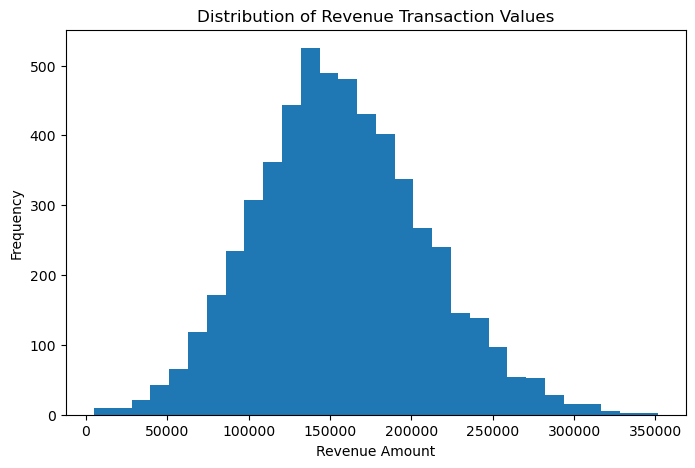

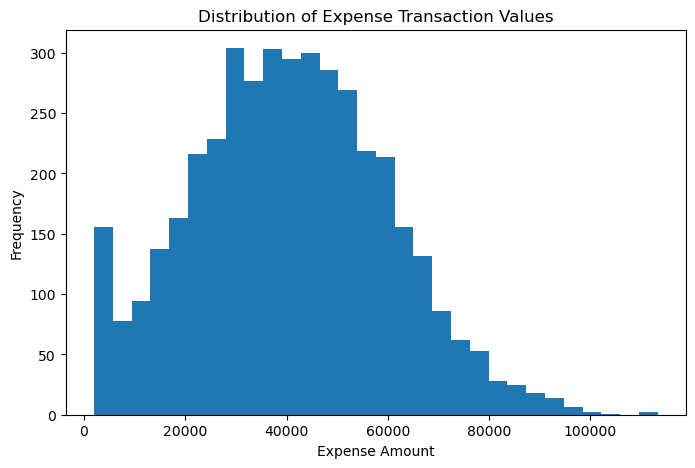

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(revenue_df["amount"], bins=30)
plt.title("Distribution of Revenue Transaction Values")
plt.xlabel("Revenue Amount")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(expense_df["amount"], bins=30)
plt.title("Distribution of Expense Transaction Values")
plt.xlabel("Expense Amount")
plt.ylabel("Frequency")
plt.show()

**Interpretation:**

**Revenue distribution**
- Most revenue transactions fall roughly between ₹100k and ₹220k.
- The distribution is fairly smooth and approximately bell-shaped.
- There is a longer tail toward higher values, extending to about ₹350k, so a few larger revenue transactions exist.
- This is consistent with the earlier statistics where the mean was slightly above the median.

**Expense distribution**
- Most expense transactions are concentrated around ₹20k–₹60k.
- There is a noticeable right tail extending beyond ₹100k, indicating some relatively large expenses.
- The small spike near the lower end is also worth noting and could be investigated later if necessary.

**Overall:** There are no visually obvious extreme anomalies that require immediate cleaning. The distributions mainly show normal variation in transaction sizes, with some larger transactions that we can investigate later as part of the anomaly/data-quality analysis.

#### 6.6.2 Monthly Profit Trend

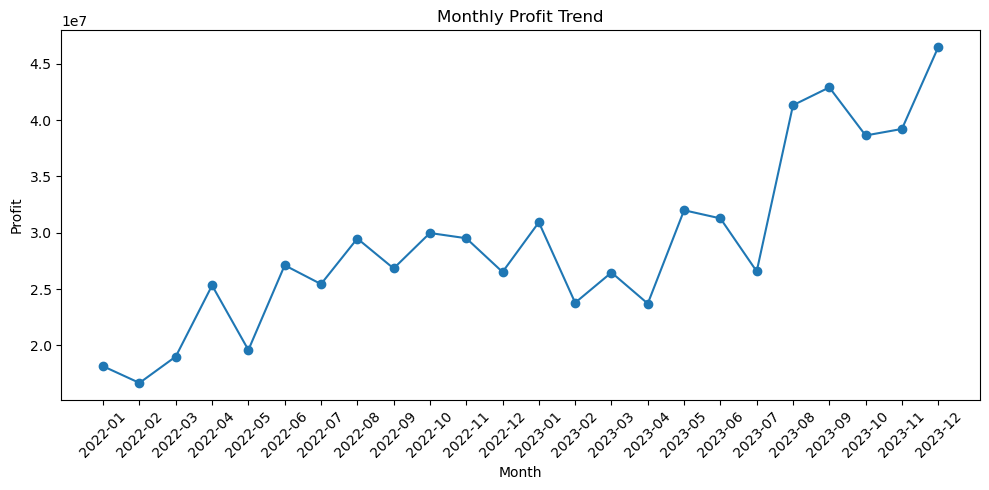

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_profit["month"].astype(str),
    monthly_profit["profit"],
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Interpretation: Monthly Profit Trend**
- Profit shows an overall upward trend from 2022 to 2023.
- In early 2022, monthly profit was around ₹17–25 million.
- During 2022, profit generally remained around ₹25–30 million, with some month-to-month fluctuations.
- In early 2023, profit still fluctuated around ₹24–32 million.
- A major improvement occurs from August 2023, when profit jumps above ₹40 million.
- December 2023 has the highest monthly profit at approximately ₹46.5 million.
- There are still short-term declines, such as September → October 2023, but the overall direction is strongly positive.

**Summary:** The company became substantially more profitable during the latter part of 2023, with the strongest performance occurring from August through December. This period could be investigated further to determine whether the increase was driven by higher revenue, lower expenses, or both.

#### 6.6.3 Budget vs Actual

In [21]:
monthly_budget = budget_variance_df.groupby(
    ["year", "month"]
)[["budgeted_revenue", "actual_revenue"]].sum()

print(monthly_budget)


            budgeted_revenue  actual_revenue
year month                                  
2022 1               5288988     25538097.88
     2               5276268     22787659.96
     3               5207076     25839878.66
     4               5906232     32862478.97
     5               5622756     26932607.33
     6               6254040     34033298.18
     7               6031800     32543433.61
     8               5999280     36856527.38
     9               5902104     32948507.24
     10              5500800     37149413.47
     11              5995596     35853481.03
     12              5424036     34080746.42
2023 1               5782380     38067348.30
     2               5483808     30059682.33
     3               5650608     33952130.14
     4               4423140     32132733.86
     5               5676156     39060302.19
     6               5888052     37710469.90
     7               5001504     33452063.44
     8               5610816     48132079.93
     9    

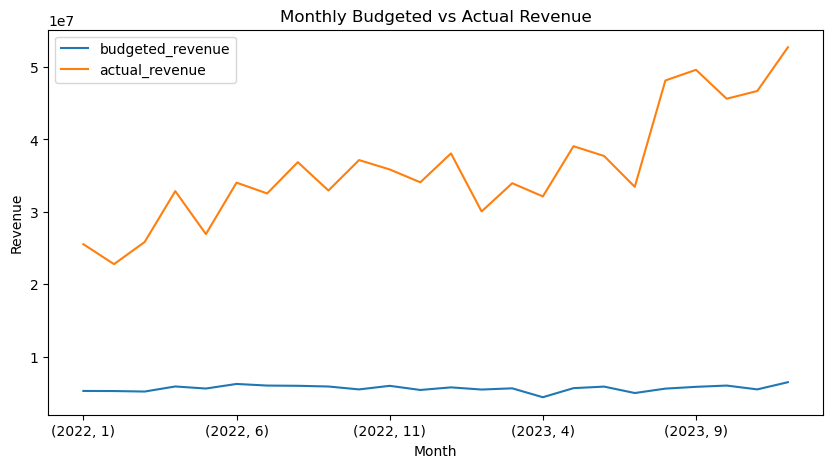

In [22]:
monthly_budget.plot(figsize=(10, 5))

plt.title("Monthly Budgeted vs Actual Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()

plt.show()

**Interpretation:**
- Actual revenue is consistently above budgeted revenue throughout the entire 2022–2023 period.
- Actual revenue generally increases over time, with particularly strong growth in the second half of 2023.
- The gap between actual and budgeted revenue is substantial, confirming the large positive revenue variances we calculated earlier.
- The highest actual revenue occurs toward the end of 2023.

**Summary:** The company consistently exceeded its revenue budget, and the gap became particularly large during late 2023. This is a significant finding that should be investigated later to determine whether it reflects genuine business outperformance or a possible issue in how the budget and transaction data are recorded.

#### 6.6.4 Budgeted vs Actual Expense

In [23]:
monthly_expense = budget_variance_df.groupby(
    ["year", "month"]
)[["budgeted_expense", "actual_expense"]].sum()

print(monthly_expense)

            budgeted_expense  actual_expense
year month                                  
2022 1               4188544      7399263.92
     2               3773062      6128841.46
     3               3744162      6837846.47
     4               4256656      7543281.98
     5               4212167      7347552.76
     6               5351773      6923308.42
     7               4618493      7103985.77
     8               4454727      7371098.00
     9               4245391      6119524.50
     10              3906312      7174351.25
     11              4540666      6342891.49
     12              4525227      7569363.14
2023 1               4421561      7139867.34
     2               4677926      6278381.32
     3               4367368      7484462.15
     4               2929340      8426719.72
     5               4230712      7062838.65
     6               4194424      6435755.34
     7               4402210      6884502.35
     8               4374577      6805884.46
     9    

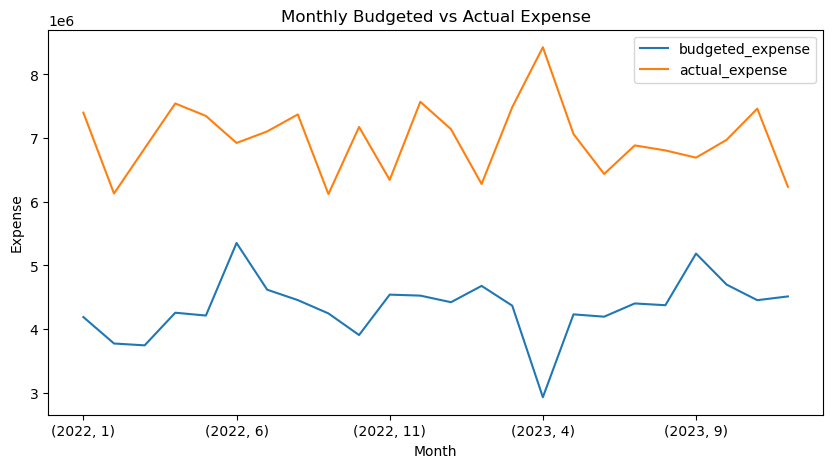

In [24]:
monthly_expense.plot(figsize=(10, 5))

plt.title("Monthly Budgeted vs Actual Expense")
plt.xlabel("Month")
plt.ylabel("Expense")
plt.legend()

plt.show()

**Interpretation: Monthly Budgeted vs Actual Expense**
- Actual expenses are above the budget in every month shown.
- The gap is consistently large, confirming our earlier finding that expense variance is generally positive.
- Actual expenses fluctuate considerably, with the highest point around April 2023.
- Budgeted expenses are comparatively stable, while actual expenses show much more variation.
- This means the company is not only exceeding its revenue budget, but is also spending more than planned.

**Summary:** Actual expenses consistently exceeded the budget throughout the period, creating unfavorable expense variances. The large and persistent gap suggests that expense control should be an important area for further investigation.

#### 6.6.5 Monthly Revenue, Expense and Profit

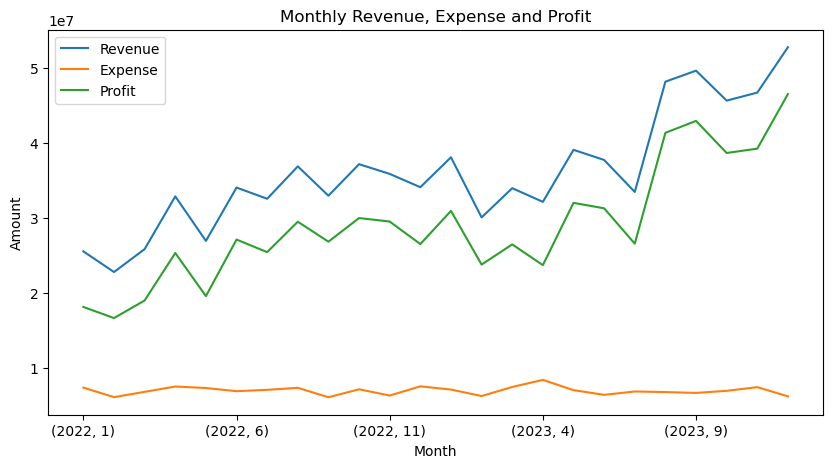

In [25]:
monthly_revenue = revenue_df.groupby(
    ["year", "month"]
)["amount"].sum()

monthly_expense = expense_df.groupby(
    ["year", "month"]
)["amount"].sum()

monthly_financials = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Expense": monthly_expense,
    "Profit": monthly_revenue - monthly_expense
})

monthly_financials.plot(figsize=(10, 5))

plt.title("Monthly Revenue, Expense and Profit")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.legend()

plt.show()

**Interpretation:**
- Revenue and profit show a clear overall upward trend across the two years.
- Expense remains much lower than revenue throughout the period.
- Because expenses stay relatively controlled while revenue increases, profit rises alongside revenue.
- The strongest improvement is again visible in the latter part of 2023.
- The final month has the highest revenue and profit in the period.

**Summary:** The company shows improving financial performance over time, with rising revenue translating into higher profit while expenses remain comparatively stable.

#### 6.6.6 Revenue and Expense by Business Unit

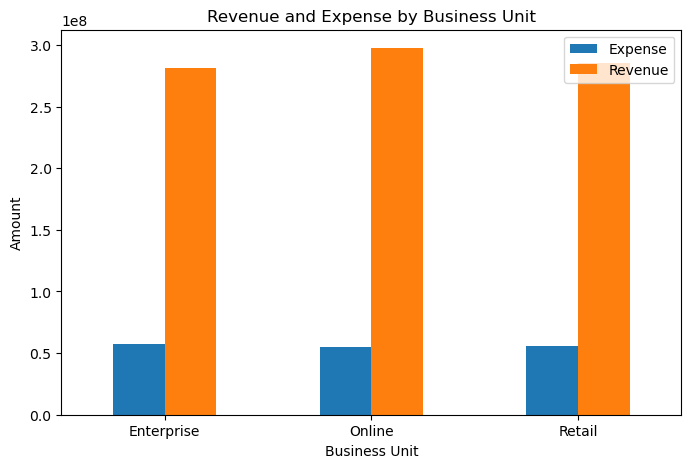

In [26]:
unit_financials = transactions_df[
    transactions_df["account_type"].isin(["Revenue", "Expense"])
].copy()

unit_financials["amount"] = unit_financials["amount"].abs()

unit_financials = unit_financials.groupby(
    ["business_unit", "account_type"]
)["amount"].sum().unstack()

unit_financials.plot(kind="bar", figsize=(8, 5))

plt.title("Revenue and Expense by Business Unit")
plt.xlabel("Business Unit")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend()

plt.show()

**Interpretation:**
- Online generates the highest total revenue among the three business units.
- Retail is very close behind Online.
- Enterprise has the lowest total revenue.
- Expenses are relatively similar across all three units.
- Because revenue differs more than expense, Online and Retail appear to generate stronger overall financial performance.

**Summary:** Online is the strongest revenue-generating business unit, followed closely by Retail, while Enterprise generates slightly less revenue. Expenses are fairly similar across the units, suggesting that the differences in overall contribution are driven mainly by revenue rather than major differences in expense levels.

#### 6.6.7 Expense by Category

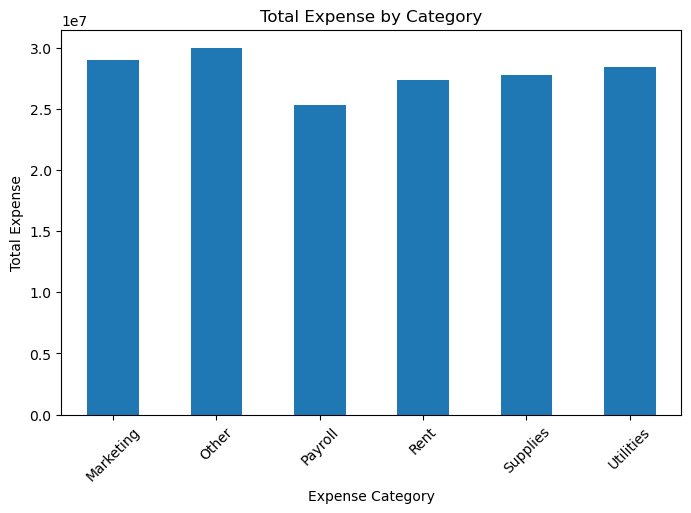

In [27]:
expense_category = expense_df.groupby(
    "category"
)["amount"].sum()

expense_category.plot(kind="bar", figsize=(8, 5))

plt.title("Total Expense by Category")
plt.xlabel("Expense Category")
plt.ylabel("Total Expense")
plt.xticks(rotation=45)

plt.show()

**Interpretation:**
- Other is the largest expense category.
- Payroll is the lowest among the six categories.
- Marketing and Utilities are also relatively large expense categories.
- The difference between the largest and smallest categories is not extremely large, so expenses are fairly distributed across categories.

**Summary:** Expense is spread across several categories, with Other representing the largest total expenditure and Payroll the smallest. This suggests there isn't one overwhelmingly dominant expense category, although the Other category may be worth investigating further because it is the largest.

### Step 7: Statistical Analysis & Hypothesis Testing

### 1. Revenue: 2022 vs 2023 (t-test)

**Business question:** Did average monthly revenue significantly increase from 2022 to 2023?

**Hypotheses:**  
- **H₀ (Null):** There is no significant difference in average monthly revenue between 2022 and 2023.  
- **H₁ (Alternative):** There is a significant difference in average monthly revenue between 2022 and 2023.

In [28]:
from scipy.stats import ttest_ind

monthly_revenue = revenue_df.groupby(
    ["year", "month"]
)["amount"].sum().reset_index()

revenue_2022 = monthly_revenue[
    monthly_revenue["year"] == 2022
]["amount"]

revenue_2023 = monthly_revenue[
    monthly_revenue["year"] == 2023
]["amount"]

print("2022 Average Revenue:", revenue_2022.mean())
print("2023 Average Revenue:", revenue_2023.mean())

2022 Average Revenue: 31452177.510833338
2023 Average Revenue: 40598538.505833335


In [29]:
t_stat, p_value = ttest_ind(
    revenue_2022,
    revenue_2023
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -3.495031562875849
P-value: 0.0020483668813906226


**Results:**  
- T-statistic = −3.495
- P-value = 0.00205
Using the standard 5% significance level (α = 0.05):  
**p-value < 0.05 → Reject H₀**

**Conclusion:**  
There is a statistically significant difference in average monthly revenue between 2022 and 2023.
Since the average monthly revenue increased from 31.45 million in 2022 to 40.60 million in 2023, the result supports the conclusion that monthly revenue was significantly higher in 2023.


**Interpretation:**  
The independent t-test showed a statistically significant difference in average monthly revenue between 2022 and 2023 (t = −3.495, p = 0.002). Therefore, the null hypothesis was rejected. Average monthly revenue increased from approximately 31.45 million in 2022 to 40.60 million in 2023, indicating a significant improvement in revenue performance.

### 2. Actual Revenue vs Budgeted Revenue

**Business question:** Did actual monthly revenue differ significantly from budgeted monthly revenue?

**Hypotheses:**  
- **H₀ (Null):** There is no significant difference between actual and budgeted monthly revenue.
- **H₁ (Alternative):** There is a significant difference between actual and budgeted monthly revenue.

In [30]:
from scipy.stats import ttest_ind

actual_revenue = monthly_budget["actual_revenue"]
budgeted_revenue = monthly_budget["budgeted_revenue"]

print("Average Actual Revenue:", actual_revenue.mean())
print("Average Budgeted Revenue:", budgeted_revenue.mean())

Average Actual Revenue: 36025358.00833333
Average Budgeted Revenue: 5658916.0


In [31]:
t_stat, p_value = ttest_ind(
    actual_revenue,
    budgeted_revenue
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 18.997919829068778
P-value: 2.0787528124071474e-23


**Results:**
- T-statistic = 18.998
- P-value = 2.08 × 10⁻²³  
Using α = 0.05:  
**p-value < 0.05 → Reject H₀**

**Conclusion:**  
There is a statistically significant difference between actual and budgeted monthly revenue.
The average actual revenue (36.03 million) was substantially higher than the average budgeted revenue (5.66 million). Therefore, the data provides strong statistical evidence that actual revenue significantly exceeded the budgeted revenue.


**Interpretation:**  
The independent t-test showed a statistically significant difference between actual and budgeted monthly revenue (t = 18.998, p < 0.001). Therefore, the null hypothesis was rejected. Actual monthly revenue averaged approximately 36.03 million compared with 5.66 million budgeted, indicating that actual revenue substantially exceeded the planned budget during the study period.

### 3. Actual Expense vs Budgeted Expense


**Business question:** Did actual monthly expenses differ significantly from budgeted monthly expenses?

**Hypotheses:**
- **H₀ (Null):** There is no significant difference between actual and budgeted monthly expenses.
- **H₁ (Alternative):** There is a significant difference between actual and budgeted monthly expenses.

In [32]:
monthly_expense_budget = budget_variance_df.groupby(
    ["year", "month"]
)[["budgeted_expense", "actual_expense"]].sum()

actual_expense = monthly_expense_budget["actual_expense"]
budgeted_expense = monthly_expense_budget["budgeted_expense"]

print("Average Actual Expense:", actual_expense.mean())
print("Average Budgeted Expense:", budgeted_expense.mean())

Average Actual Expense: 6989220.825
Average Budgeted Expense: 4344386.208333333


In [33]:
t_stat, p_value = ttest_ind(
    actual_expense,
    budgeted_expense
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 17.72066376948806
P-value: 3.502950018507109e-22


**Results:**
- T-statistic = 17.721
- P-value = 3.50 × 10⁻²²

Using α = 0.05:
**p-value < 0.05 → Reject H₀**

**Conclusion:**  
There is a statistically significant difference between actual and budgeted monthly expenses.
The average actual expense was 6.99 million, compared with a budgeted expense of 4.34 million. Since actual expenses were higher, this indicates that the business significantly exceeded its expense budget during the study period.


**Interpretation:**  
The independent t-test showed a statistically significant difference between actual and budgeted monthly expenses (t = 17.721, p < 0.001). Therefore, the null hypothesis was rejected. Actual monthly expenses averaged approximately 6.99 million compared with 4.34 million budgeted, indicating that actual expenses significantly exceeded the planned budget.

### 4. Revenue Across Business Units


**Business question:** Is there a significant difference in average revenue among the three business units?

**Hypotheses:**  
- **H₀ (Null):** The mean revenue is the same across all business units.
- **H₁ (Alternative):** At least one business unit has a significantly different mean revenue.

In [34]:
from scipy.stats import f_oneway

enterprise_revenue = revenue_df[
    revenue_df["business_unit"] == "Enterprise"
]["amount"]

online_revenue = revenue_df[
    revenue_df["business_unit"] == "Online"
]["amount"]

retail_revenue = revenue_df[
    revenue_df["business_unit"] == "Retail"
]["amount"]

print("Enterprise Average Revenue:", enterprise_revenue.mean())
print("Online Average Revenue:", online_revenue.mean())
print("Retail Average Revenue:", retail_revenue.mean())

Enterprise Average Revenue: 155640.0468141593
Online Average Revenue: 162853.26804597702
Retail Average Revenue: 152037.50230973924


In [35]:
f_stat, p_value = f_oneway(
    enterprise_revenue,
    online_revenue,
    retail_revenue
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 20.866610529154695
P-value: 9.373178000399536e-10


**Results:**
- F-statistic = 20.867
- P-value = 9.37 × 10⁻¹⁰

Using α = 0.05:  
**p-value < 0.05 → Reject H₀**

**Conclusion:**  
There is a statistically significant difference in average revenue among the three business units.
Although the average transaction values were:
- Enterprise: 155,640
- Online: 162,853
- Retail: 152,038
the ANOVA indicates that these differences are unlikely to be due to random variation alone.


**Interpretation:**  
A one-way ANOVA showed a statistically significant difference in average revenue across Enterprise, Online, and Retail business units (F = 20.867, p < 0.001). Therefore, the null hypothesis was rejected, indicating that average revenue differs significantly among the business units.

### 5. Expense Category Mix Across Business Units


**Business question:** Is expense category associated with business unit? Or, do Enterprise, Online, and Retail have different patterns in how their expenses are distributed across categories?


**Hypotheses:**  
- **H₀ (Null):** Expense category and business unit are independent. There is no significant association between them.
- **H₁ (Alternative):** Expense category and business unit are not independent. There is a significant association between them.

In [36]:
from scipy.stats import chi2_contingency

expense_table = pd.crosstab(
    expense_df["business_unit"],
    expense_df["category"]
)

print(expense_table)

category       Marketing  Other  Payroll  Rent  Supplies  Utilities
business_unit                                                      
Enterprise           240    247      235   221       227        238
Online               232    250      202   222       231        227
Retail               226    227      215   216       230        239


In [37]:
chi2_stat, p_value, dof, expected = chi2_contingency(
    expense_table
)

print("Chi-square statistic:", chi2_stat)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 3.541636743298159
P-value: 0.9656656758723045
Degrees of freedom: 10


**Results:**
- Chi-square statistic = 3.542
- Degrees of freedom = 10
- P-value = 0.966

Using α = 0.05:  
**p-value > 0.05 → Fail to reject H₀**

**Conclusion:**
There is no statistically significant association between business unit and expense category.
In other words, the distribution of expense categories is broadly similar across Enterprise, Online, and Retail. The differences in the transaction counts we observed are small enough that they could reasonably be due to random variation.


**Interpretation:**
The chi-square test of independence found no statistically significant association between business unit and expense category (χ² = 3.542, df = 10, p = 0.966). Therefore, the null hypothesis was not rejected. This indicates that the distribution of expense categories is broadly similar across Enterprise, Online, and Retail business units.